---

# Tugas Besar 2 IF3170 Inteligensi Artifisial

*This notebook is the assignment template. Each group works on its own copy, and cells or sections may be added as needed.*

---

## Group OISCDivisiKaggle

- Nathan Adhika Santosa (13524041)
- Renuno Yuqa Frinardi (13524080)
- Timothy Bernard Soeharto (13524092)
- Valentino Daniel Kusumo (13524104)
- Leonardus Brain Fatolosja (13524146)

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)


---

# Introduction <a name="1"></a>

---

This section frames the problem in the words of the group.

## Overview

This dataset contains hotel booking records used to predict whether a
reservation will be canceled (`is_canceled = 1`) or not (`is_canceled = 0`).
Accurate predictions can help hotels forecast room demand, manage
cancellation risks, and plan operational strategies as well as guest offers.
The analysis uses booking attributes, guest characteristics, arrival
schedules, booking channels, booking history, nightly rates, and special
requests.

## Aim

The aim of this assignment is to build and compare several classification
models—both from-scratch implementations and benchmark library models—to
accurately predict booking cancellations on the validation and test sets.

## Metric

The primary metric used is accuracy, as it follows standard classification evaluation. Because the target distribution is imbalanced (around 67% non-canceled and 33% canceled), the positive-class F1-score, along with precision and recall, is also used to evaluate how well each model detects canceled bookings.


## Dataset

The data is split into `train.csv` and `test.csv`. `train.csv` contains 19
columns, including the target `is_canceled`, whereas `test.csv` contains 18
predictor columns without the target. The `id` column is read as a string
and excluded from the model features.
Nominal features such as `meal_package`, `room_category`, and
`booking_channel` have no inherent ordering and are one-hot encoded. Binary
features are represented by `0` and `1`, while guest counts, length of stay,
lead time, nightly rates, booking history, and special requests are treated
as numeric features.

## Approach

The workflow consists of a stratified train-validation split, data quality
analysis, data cleaning, missing-value imputation, numeric feature
standardization, one-hot encoding of categorical features, validation across
multiple models, hyperparameter tuning, best-model selection, and Kaggle
submission generation. All preprocessing statistics are computed strictly on
the training data to prevent *data leakage* from the validation or test sets.

---

# Initialization <a name="2"></a>

---

This section prepares the environment, the settings, and the data files.

## Environment Setup

The following cell lists the base libraries. The install line is commented by default.

In [ ]:
%pip install numpy pandas matplotlib qpsolvers osqp scikit-learn

Note: you may need to restart the kernel to use updated packages.


## Import Libraries

Every import of the notebook is kept in this cell.

In [ ]:
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd

import sys
from IPython.display import display
import matplotlib.pyplot as plt
import pickle

from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from inspect import signature
from sklearn.metrics import f1_score
from sklearn.model_selection import ParameterGrid, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression as SklearnLR
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support



## Settings

Paths and shared constants are kept in this class.

In [ ]:
class Settings:
    ROOT = next(
        (path for path in (Path.cwd(), *Path.cwd().parents)
         if (path / "src" / "notebook.ipynb").is_file() and (path / "dataset").is_dir()),
        None,
    )
    if ROOT is None:
        raise FileNotFoundError("Start the notebook from the repository root or src/.")

    SEED = 42
    DATA_DIR = ROOT / "dataset"
    OUTPUT_DIR = Path(os.environ.get("MAIN_OUTPUT_DIR", ROOT / "output"))
    TARGET = "is_canceled"
    ID = "id"

CFG = Settings()
if str(CFG.ROOT) not in sys.path:
    sys.path.insert(0, str(CFG.ROOT))
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Import Local Algorithms
from src.decision_tree import DecisionTree
from src.decision_tree.optimized.decision_tree import DecisionTree as OptimizedTree
from src.decision_tree.tree_visualization import plot_decision_tree
from src.logistic_regression.logistic_regression import LogisticRegression
from src.logistic_regression.optimized import LROptimized
from src.svm.svm import SVM
from src.naive_bayes import NaiveBayes
from src.knn.knn import KNN

## Seed Everything

A fixed seed keeps the results reproducible.

In [ ]:
def seed_everything(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    return np.random.default_rng(seed)

split_rng = seed_everything(CFG.SEED)

## Load Dataset

The competition files are read here. The `id` column stays as text because some values resemble numbers.

In [ ]:
train_df = pd.read_csv(CFG.DATA_DIR / "train.csv", dtype={'id': str})
test_df = pd.read_csv(CFG.DATA_DIR / "test.csv", dtype={'id': str})

# Data cleaning dasar yang semantik: nilai tanpa tamu dewasa tidak valid,
# sedangkan nilai 0 pada harga hanya diperlakukan sebagai missing bila
# booking bukan Complimentary.
for frame in (train_df, test_df):
    frame.loc[frame["num_adults"].eq(0), "num_adults"] = np.nan
    missing_rate = frame["nightly_rate_idr"].eq(0) & frame["booking_channel"].ne("Complimentary")
    frame.loc[missing_rate, "nightly_rate_idr"] = np.nan

print(f'Train: {train_df.shape}  Test: {test_df.shape}')


Train: (27373, 19)  Test: (6844, 18)


---

# Data Understanding<a name="3"></a>

---

Data understanding builds the knowledge that later preparation decisions rest on.

## Describe Data

This part covers the size, the attribute types, and the meaning of each column.

In [ ]:
display(pd.DataFrame({
    "rows": [len(train_df), len(test_df)],
    "columns": [train_df.shape[1], test_df.shape[1]],
}, index=["train", "test"]))
display(train_df.head())

describe_features = train_df.drop(columns=[CFG.ID, CFG.TARGET])
describe_numeric = describe_features.select_dtypes(include="number").columns
display(pd.DataFrame({
    "role": ["ID" if col == CFG.ID else "target" if col == CFG.TARGET
             else "numeric" if col in describe_numeric else "categorical"
             for col in train_df.columns],
    "dtype": train_df.dtypes.astype(str),
    "unique_values": train_df.nunique(),
}))

display(describe_features.describe(include="number").T)
display(describe_features.select_dtypes(exclude="number").describe().T)

,rows,columns
train,27373,19
test,6844,18


,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
0,57152f82,2.0,NaN,1,2,Breakfast,0.0,Type B,88.0,2024,4,3,Offline Agent,0,0,0,1330000.0,0.0,1
1,af2ec71b,2.0,0.0,2,1,Half Board,0.0,Type D,120.0,2023,8,1,Offline Agent,0,0,0,NaN,0.0,0
2,5d5469ab,3.0,0.0,1,2,Breakfast,0.0,Type G,209.0,2024,8,28,Online Travel Agent,0,0,0,2099000.0,0.0,1
3,d2df0369,2.0,1.0,2,1,Breakfast,0.0,Type G,93.0,2024,8,13,Online Travel Agent,0,0,0,1693000.0,2.0,0
4,91d253db,2.0,0.0,0,1,Room Only,0.0,Type B,14.0,2024,9,1,Online Travel Agent,0,0,0,2010000.0,2.0,0


,role,dtype,unique_values
id,ID,str,27373
num_adults,numeric,float64,4
num_children,numeric,float64,6
weekend_nights,numeric,int64,8
weekday_nights,numeric,int64,18
meal_package,categorical,str,4
needs_parking,numeric,float64,2
room_category,categorical,str,7
days_before_arrival,numeric,float64,407
arrival_year,numeric,int64,2


,count,mean,std,min,25%,50%,75%,max
num_adults,26458.0,1.852634e+00,0.505644,1.0,2.0,2.0,2.0,4.0
num_children,24338.0,1.173884e-01,0.425761,0.0,0.0,0.0,0.0,10.0
weekend_nights,27373.0,8.148541e-01,0.875146,0.0,0.0,1.0,2.0,7.0
weekday_nights,27373.0,2.206517e+00,1.421603,0.0,1.0,2.0,3.0,17.0
needs_parking,26291.0,3.020045e-02,0.171142,0.0,0.0,0.0,0.0,1.0
days_before_arrival,26250.0,8.537943e+01,85.969638,0.0,17.0,58.0,126.0,448.0
arrival_year,27373.0,2.023820e+03,0.384099,2023.0,2024.0,2024.0,2024.0,2024.0
arrival_month,27373.0,7.399664e+00,3.074788,1.0,5.0,8.0,10.0,12.0
arrival_day,27373.0,1.553754e+01,8.773321,1.0,8.0,16.0,23.0,31.0
is_returning_guest,27373.0,2.517079e-02,0.156646,0.0,0.0,0.0,0.0,1.0


,count,unique,top,freq
meal_package,25613,4,Breakfast,19654
room_category,26371,7,Type B,20447
booking_channel,27373,5,Online Travel Agent,17511


## Explore Data

This part covers distributions and relationships between attributes.

,count,share
is_canceled,,
0,18404,0.672341
1,8969,0.327659


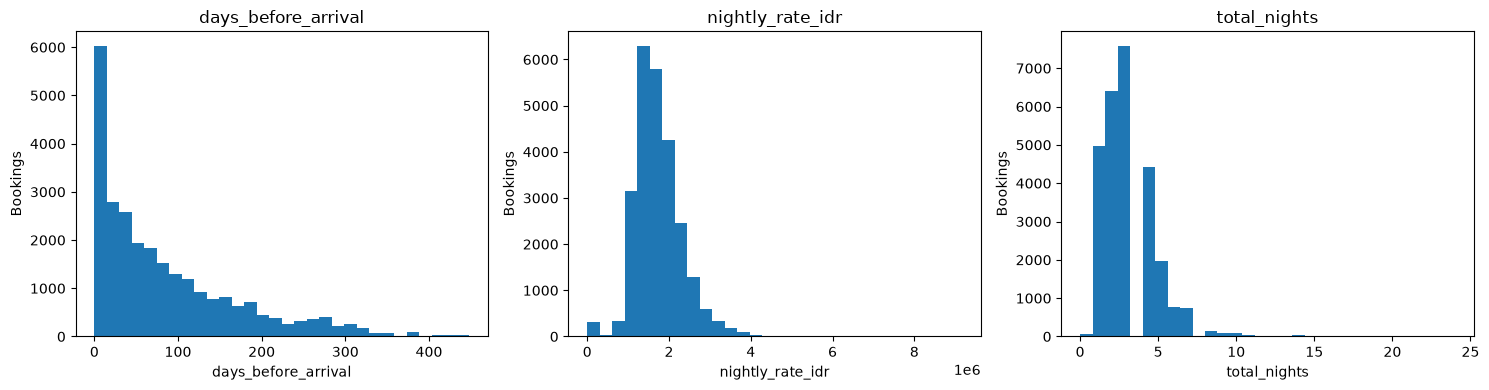

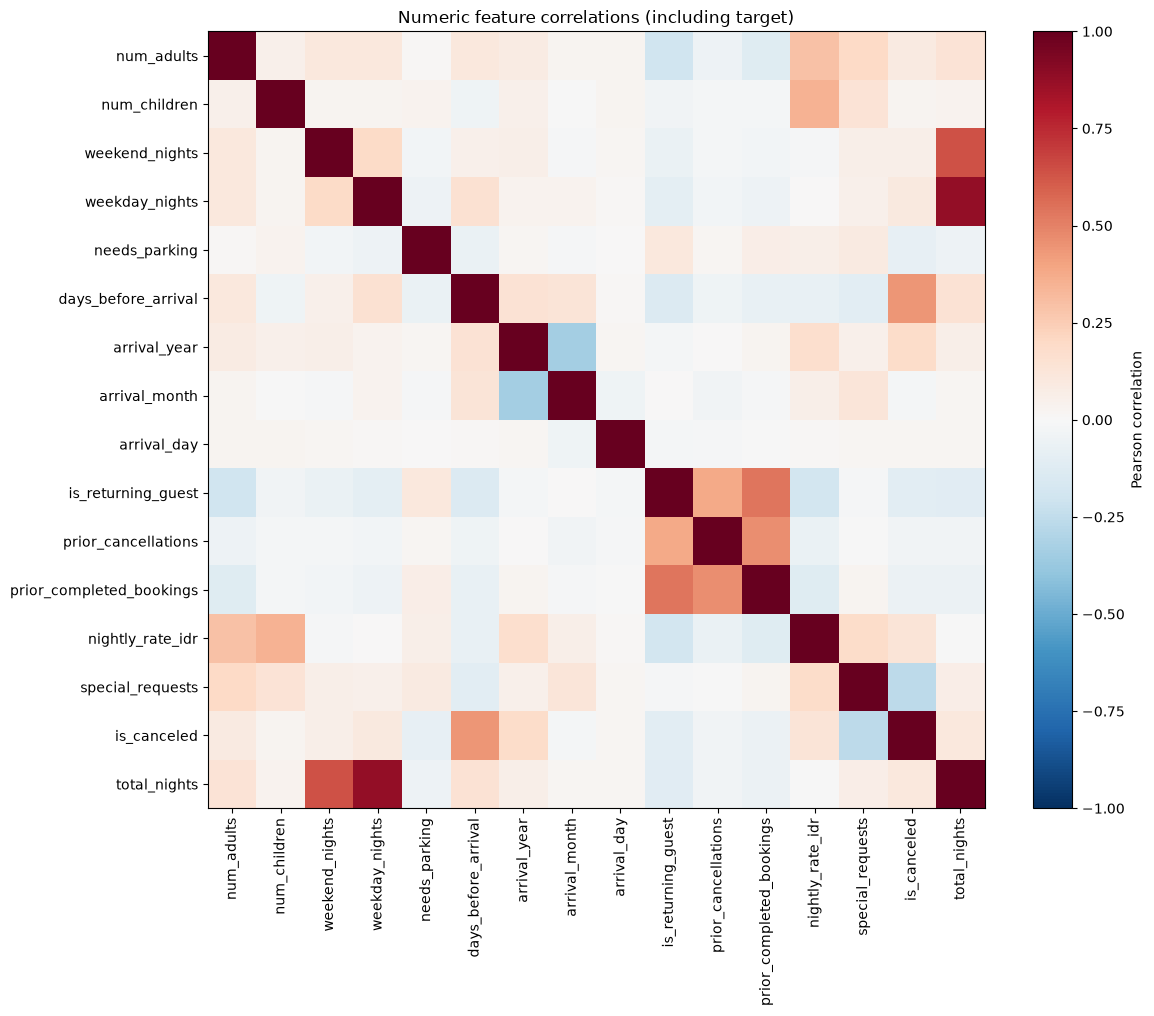

In [ ]:
# Target Distribution
display(train_df[CFG.TARGET].value_counts().sort_index().to_frame("count").assign(
    share=lambda counts: counts["count"] / counts["count"].sum(),
))


# Numeric Feature Distribution
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column in zip(axes, ["days_before_arrival", "nightly_rate_idr", "total_nights"]):
    if column == "total_nights":
        (train_df["weekday_nights"] + train_df["weekend_nights"]).plot.hist(bins=30, ax=ax)
    else:
        train_df[column].plot.hist(bins=30, ax=ax)
    ax.set(title=column, xlabel=column, ylabel="Bookings")
fig.tight_layout()
plt.show()

# Pearson Correlation between Numeric Features
plt.figure(figsize=(12, 10))
plt.imshow(train_df.assign(
    total_nights=train_df["weekday_nights"] + train_df["weekend_nights"],
).drop(columns=CFG.ID).corr(numeric_only=True), vmin=-1, vmax=1, cmap="RdBu_r")
plt.xticks(
    range(len(train_df.select_dtypes(include="number").columns) + 1),
    [*train_df.select_dtypes(include="number").columns, "total_nights"], rotation=90,
)
plt.yticks(
    range(len(train_df.select_dtypes(include="number").columns) + 1),
    [*train_df.select_dtypes(include="number").columns, "total_nights"],
)
plt.title("Numeric feature correlations (including target)")
plt.colorbar(label="Pearson correlation")
plt.tight_layout()
plt.show()

## Verify Data Quality

This part covers completeness, consistency, and the validity of values.

In [ ]:
# Missing values
display(pd.concat({
    "train": pd.DataFrame({"count": train_df.isna().sum(), "percent": train_df.isna().mean().mul(100)}),
    "test": pd.DataFrame({"count": test_df.isna().sum(), "percent": test_df.isna().mean().mul(100)}),
}, axis=1).round(2))

# Duplicate
display(pd.DataFrame({
    name: {
        f"{CFG.ID} missing": frame[CFG.ID].isna().sum(),
        f"{CFG.ID} duplicate": frame[CFG.ID].dropna().duplicated().sum(),
        "Rows with duplicates": frame.duplicated().sum(),
        "Repeated Predicator": frame.duplicated(subset=test_df.columns.drop(CFG.ID)).sum(),
    }
    for name, frame in (("train", train_df), ("test", test_df))
}))

# Zero Value
for name, frame in (("train", train_df), ("test", test_df)):
    print(name)
    display(pd.Series({
        "num_adults = 0": frame["num_adults"].eq(0).sum(),
        "weekday_nights + weekend_nights = 0": (frame["weekday_nights"] + frame["weekend_nights"]).eq(0).sum(),
        "nightly_rate_idr = 0": frame["nightly_rate_idr"].eq(0).sum(),
        "arrival_year/month/day not valid or empty": pd.to_datetime({
            "year": frame["arrival_year"],
            "month": frame["arrival_month"],
            "day": frame["arrival_day"],
        }, errors="coerce").isna().sum(),
    }))
    display(pd.Series({
        column: (frame[column].notna() & ~frame[column].isin([0, 1])).sum()
        for column in ("needs_parking", "is_returning_guest")
    }, name="Values other than 0/1 (without missing)"))


train           test        
                         count percent  count percent
id                           0    0.00    0.0    0.00
num_adults                 915    3.34  202.0    2.95
num_children              3035   11.09  747.0   10.91
weekend_nights               0    0.00    0.0    0.00
weekday_nights               0    0.00    0.0    0.00
meal_package              1760    6.43  442.0    6.46
needs_parking             1082    3.95  247.0    3.61
room_category             1002    3.66  242.0    3.54
days_before_arrival       1123    4.10  290.0    4.24
arrival_year                 0    0.00    0.0    0.00
arrival_month                0    0.00    0.0    0.00
arrival_day                  0    0.00    0.0    0.00
booking_channel              0    0.00    0.0    0.00
is_returning_guest           0    0.00    0.0    0.00
prior_cancellations          0    0.00    0.0    0.00
prior_completed_bookings     0    0.00    0.0    0.00
nightly_rate_idr          2184    7.98  566.0    8.27
special_requests          2500    9.13  593.0    8.66
is_canceled                  0    0.00    NaN     NaN

,train,test
id kosong,0,0
id duplikat (tanpa missing),0,0
Baris duplikat lengkap,0,0
Prediktor berulang,66,3


train


num_adults = 0                                      0
weekday_nights + weekend_nights = 0                64
nightly_rate_idr = 0                              267
arrival_year/month/day tidak valid atau kosong      0
dtype: int64

needs_parking         0
is_returning_guest    0
Name: Nilai selain 0/1 (tanpa missing), dtype: int64

test


num_adults = 0                                     0
weekday_nights + weekend_nights = 0                9
nightly_rate_idr = 0                              59
arrival_year/month/day tidak valid atau kosong     0
dtype: int64

needs_parking         0
is_returning_guest    0
Name: Nilai selain 0/1 (tanpa missing), dtype: int64

---

# Training and Validation Split <a name="4"></a>

---

The split comes before data preparation so that validation data stays unseen. Only `train.csv` is split, and `test.csv` serves the Kaggle submission alone.

In [ ]:
train_set, val_set = train_test_split(
    train_df,
    test_size = 0.2,
    stratify = train_df[CFG.TARGET],
    random_state = CFG.SEED
)

---

# Data Preparation <a name="5"></a>

---

Each process below applies where the data calls for it, and the Insights block under it records the reason for the decision.

Preparation steps may use `sklearn`. Every statistic comes from the training split only, then transforms the other sets.

## Select Data

Selection decides which records and attributes stay in the analysis.

In [ ]:
X_train = train_set.drop(columns=[CFG.ID, CFG.TARGET]).copy()
X_val = val_set.drop(columns=[CFG.ID, CFG.TARGET]).copy()
y_train = train_set[CFG.TARGET].copy()
y_val = val_set[CFG.TARGET].copy()

## Clean Data

Cleaning raises data quality to the level the chosen models need.

### Missing Values

This part covers missing values, if any.

In [ ]:
numeric_columns = X_train.select_dtypes(include="number").columns.tolist()
categorical_columns = X_train.columns.difference(numeric_columns, sort=False).tolist()

missing_imputer = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True), numeric_columns),
    ("categorical", SimpleImputer(strategy="constant", fill_value="<missing>", keep_empty_features=True), categorical_columns),
], verbose_feature_names_out=False).set_output(transform="pandas")

X_train = missing_imputer.fit_transform(X_train)
X_val = missing_imputer.transform(X_val)

### Duplicates

This part covers repeated records.

In [ ]:
# [No duplicate handling due to lack of duplicates in the dataset]
display(pd.Series({
    "train_duplicate_rows": train_set.duplicated().sum(),
    "validation_duplicate_rows": val_set.duplicated().sum(),
    "train_repeated_predictors": train_set.drop(columns=[CFG.ID, CFG.TARGET]).duplicated().sum(),
}, name="count"))


train_duplicate_rows          0
validation_duplicate_rows     0
train_repeated_predictors    41
Name: count, dtype: int64

### Outliers

This part covers values far from the rest of the data.

In [ ]:
# [Doesn't handle outliers, due to lack of outliers]
display(X_train[numeric_columns].describe(percentiles=[0.01, 0.5, 0.99]).T[
    ["min", "1%", "50%", "99%", "max"]
])


,min,1%,50%,99%,max
num_adults,1.0,1.0,2.0,3.00,4.0
num_children,0.0,0.0,0.0,2.00,10.0
weekend_nights,0.0,0.0,1.0,2.00,7.0
weekday_nights,0.0,0.0,2.0,6.00,17.0
needs_parking,0.0,0.0,0.0,1.00,1.0
days_before_arrival,0.0,0.0,57.0,342.03,448.0
arrival_year,2023.0,2023.0,2024.0,2024.00,2024.0
arrival_month,1.0,1.0,8.0,12.00,12.0
arrival_day,1.0,1.0,16.0,31.00,31.0
is_returning_guest,0.0,0.0,0.0,1.00,1.0


### Data Errors

This part covers wrong types, inconsistent labels, and impossible values.

In [ ]:
# Check for data errors in the raw dataset after basic semantic cleaning
def audit_data_errors(frame):
    binary_columns = ["needs_parking", "is_returning_guest"]
    invalid_binary = pd.Series({
        column: int((frame[column].notna() & ~frame[column].isin([0, 1])).sum())
        for column in binary_columns
    })

    valid_dates = pd.to_datetime(
        {
            "year": frame["arrival_year"],
            "month": frame["arrival_month"],
            "day": frame["arrival_day"],
        },
        errors="coerce",
    )

    report = pd.Series({
        "num_adults_zero": int(frame["num_adults"].eq(0).sum()),
        "zero_nights": int((frame["weekday_nights"].fillna(0) +
                            frame["weekend_nights"].fillna(0)).eq(0).sum()),
        "zero_rate_non_complimentary": int(
            (frame["nightly_rate_idr"].eq(0) &
             frame["booking_channel"].ne("Complimentary")).sum()
        ),
        "invalid_or_missing_arrival_date": int(valid_dates.isna().sum()),
    })
    return report, invalid_binary

for name, frame in (("train", train_df), ("test", test_df)):
    report, invalid_binary = audit_data_errors(frame)
    print(name)
    display(report.to_frame("count"))
    display(invalid_binary.to_frame("invalid_values"))

# Zero values in num_adults have already been converted to missing so they
# are handled by the median imputer. Zero rates for Complimentary bookings
# are retained because they carry valid domain meaning.


train


,count
num_adults_zero,0
zero_nights,64
zero_rate_non_complimentary,0
invalid_or_missing_arrival_date,0


,invalid_values
needs_parking,0
is_returning_guest,0


test


,count
num_adults_zero,0
zero_nights,9
zero_rate_non_complimentary,0
invalid_or_missing_arrival_date,0


,invalid_values
needs_parking,0
is_returning_guest,0


## Construct Data

Construction derives attributes and transforms values for modeling.

### Attribute Construction

This part covers new attributes derived from existing ones.

In [ ]:
def construct_features(frame):
    frame = frame.copy()
    frame["total_nights"] = frame["weekday_nights"] + frame["weekend_nights"]
    frame["total_guests"] = frame["num_adults"].fillna(0) + frame["num_children"].fillna(0)
    frame["weekend_night_ratio"] = (
        frame["weekend_nights"] / frame["total_nights"].replace(0, np.nan)
    )
    frame["price_per_guest"] = (
        frame["nightly_rate_idr"] / frame["total_guests"].replace(0, np.nan)
    )
    frame["prior_cancellation_rate"] = (
        frame["prior_cancellations"] /
        (frame["prior_cancellations"] + frame["prior_completed_bookings"]).replace(0, np.nan)
    )
    frame["has_special_request"] = (frame["special_requests"] > 0).astype(float)
    frame["net_prior_bookings"] = (
        frame["prior_completed_bookings"] - frame["prior_cancellations"]
    )
    arrival_dates = pd.to_datetime(
        {
            "year": frame["arrival_year"],
            "month": frame["arrival_month"],
            "day": frame["arrival_day"],
        },
        errors="coerce",
    )
    frame["is_weekend_arrival"] = arrival_dates.dt.dayofweek.isin([4, 5, 6]).astype(float)
    frame["lead_time_category"] = pd.cut(
        frame["days_before_arrival"],
        bins=[-1, 7, 30, 90, 180, np.inf],
        labels=False,
    )
    frame["arrival_month_sin"] = np.sin(2 * np.pi * frame["arrival_month"] / 12)
    frame["arrival_month_cos"] = np.cos(2 * np.pi * frame["arrival_month"] / 12)
    derived_numeric = [
        "weekend_night_ratio", "price_per_guest",
        "prior_cancellation_rate", "has_special_request",
        "net_prior_bookings", "is_weekend_arrival",
        "lead_time_category",
        "arrival_month_sin", "arrival_month_cos",
    ]
    for column in derived_numeric:
        frame[column] = frame[column].replace([np.inf, -np.inf], np.nan)
        frame[column] = frame[column].fillna(0)
    return frame

X_train = construct_features(X_train)
X_val = construct_features(X_val)
numeric_columns = numeric_columns + [
    "total_nights",
    "total_guests",
    "weekend_night_ratio",
    "price_per_guest",
    "prior_cancellation_rate",
    "has_special_request",
    "net_prior_bookings",
    "is_weekend_arrival",
    "lead_time_category",
    "arrival_month_sin",
    "arrival_month_cos",
]

### Feature Scaling

This part covers normalization to the range 0 to 1 and standardization.

In [ ]:
def scale_features(frame, means, scales):
    frame = frame.copy()
    frame[means.index] = frame[means.index].replace([np.inf, -np.inf], np.nan)
    frame[means.index] = frame[means.index].fillna(means)
    frame[means.index] = (frame[means.index] - means) / scales
    return frame

numeric_means = X_train[numeric_columns].mean()
numeric_scales = X_train[numeric_columns].std(ddof=0).replace(0, 1.0)

X_train = scale_features(X_train, numeric_means, numeric_scales)
X_val = scale_features(X_val, numeric_means, numeric_scales)


### Encoding

This part covers the numeric representation of categorical attributes.

In [ ]:
def encode_features(frame, levels):
    frame = frame.assign(**{
        column: pd.Categorical(frame[column], categories=categories)
        for column, categories in levels.items()
    })
    return pd.get_dummies(frame, columns=list(levels), dtype=float)

category_levels = {
    column: sorted(set(X_train[column]) | {"<missing>"})
    for column in categorical_columns
}
X_train = encode_features(X_train, category_levels)
X_val = encode_features(X_val, category_levels)

### Dimensionality Reduction

This step is not required because the number of features in the dataset can still be handled effectively by the models.

## Class Balance

This part covers the proportion of each class in the training data.

In [ ]:
display(pd.DataFrame({
    "count": y_train.value_counts(),
    "share": y_train.value_counts(normalize=True),
}).sort_index())


,count,share
is_canceled,,
0,14723,0.672345
1,7175,0.327655


## Format Data

Formatting produces the structure the models read, such as a numeric matrix.

In [ ]:
X_train = X_train.astype(float)
X_val = X_val.astype(float)
y_train = y_train.astype(int)
y_val = y_val.astype(int)
print(f"Training: {X_train.shape}\nvalidation: {X_val.shape}")

Training: (21898, 47)
validation: (5475, 47)


---

# Preparation Pipeline <a name="6"></a>

---

The pipeline combines the preparation steps so they run in one consistent order.

In [ ]:
def fit_preparation(raw):
    imputer = clone(missing_imputer).fit(raw)
    frame = construct_features(imputer.transform(raw))
    numeric_columns = raw.select_dtypes(include="number").columns.tolist() + [
        "total_nights",
        "total_guests",
        "weekend_night_ratio",
        "price_per_guest",
        "prior_cancellation_rate",
        "has_special_request",
        "net_prior_bookings",
        "is_weekend_arrival",
        "lead_time_category",
        "arrival_month_sin",
        "arrival_month_cos",
    ]
    categorical = raw.select_dtypes(exclude="number").columns
    return {
        "features": raw.columns.tolist(),
        "imputer": imputer,
        "means": frame[numeric_columns].mean(),
        "scales": frame[numeric_columns].std(ddof=0).replace(0, 1.0),
        "categories": {
            column: sorted(set(frame[column]) | {"<missing>"})
            for column in categorical
        },
    }

def prepare(raw, state):
    frame = state["imputer"].transform(raw[state["features"]])
    frame = construct_features(frame)
    frame = scale_features(frame, state["means"], state["scales"])
    prepared = encode_features(frame, state["categories"]).astype(float)
    prepared = prepared.replace([np.inf, -np.inf], np.nan).fillna(0.0)
    if not np.isfinite(prepared.to_numpy(dtype=float)).all():
        raise ValueError("Prepared matrix contains non-finite values")
    return prepared

X_train_raw = train_set.drop(columns=[CFG.ID, CFG.TARGET])
X_val_raw = val_set.drop(columns=[CFG.ID, CFG.TARGET])
X_test_raw = test_df.drop(columns=CFG.ID)

preparation = fit_preparation(X_train_raw)
X_train = prepare(X_train_raw, preparation)
X_val = prepare(X_val_raw, preparation)
X_test = prepare(X_test_raw, preparation)
print(f"Prepared matrices: train {X_train.shape}, validation {X_val.shape}, test {X_test.shape}")

Prepared matrices: train (21898, 47), validation (5475, 47), test (6844, 47)


---

# Modeling and Validation <a name="7"></a>

---

The target is `is_canceled`. The models here are implemented from scratch, with math libraries such as NumPy.

In [ ]:
fitted_models = {}
valid_predictions = {}

## K-Nearest Neighbors

This part covers the nearest neighbor classifier and its validation.

In [ ]:
# Parameter
knn_params = dict(n_neighbors=5)

# Training and Validation
model = KNN(**knn_params).fit(X_train, y_train)

predictions = model.predict(X_val)
fitted_models["KNN"] = model
valid_predictions["KNN"] = predictions

print(f"KNN: validation accuracy = {np.mean(predictions == y_val.to_numpy()):.4f}")

KNN: validation accuracy = 0.8325


## Decision Tree Learning

This part covers one chosen variant, which is ID3, C4.5, or CART, and its validation.

In [ ]:
# Parameter
tree_params = dict(max_depth=10, min_samples_leaf=20, random_state=CFG.SEED)

for name, model_class in (
    ("Decision Tree", DecisionTree),
    ("Optimized Decision Tree", OptimizedTree),
):
    model = model_class(**tree_params).fit(X_train, y_train)
    predictions = model.predict(X_val)

    fitted_models[name] = model
    valid_predictions[name] = predictions

    print(f"{name}: validation accuracy = {np.mean(predictions == y_val.to_numpy()):.4f}")

Decision Tree: validation accuracy = 0.8437
Optimized Decision Tree: validation accuracy = 0.8457


## Logistic Regression

This part covers the model with L1, L2, and Elastic Net regularization.

In [ ]:

# Model Parameter
lr_candidates = {
    "Logistic regression (L2)": (LogisticRegression, dict(
        penalty="l2", alpha=0.001, batch_size=256, max_iter=100, random_state=CFG.SEED,
    )),
}
for penalty in ("l1", "l2", "elasticnet"):
    lr_candidates[f"Optimized logistic regression ({penalty})"] = (LROptimized, dict(
        penalty=penalty, alpha=0.001, max_iter=100, random_state=CFG.SEED,
    ))

# Training and Validation
for name, (model_class, params) in lr_candidates.items():
    model = model_class(**params).fit(X_train, y_train)

    predictions = model.predict(X_val)
    fitted_models[name] = model
    valid_predictions[name] = predictions

    print(f"{name}: validation accuracy = {np.mean(predictions == y_val.to_numpy()):.4f}")

Logistic regression (L2): validation accuracy = 0.7907
Optimized logistic regression (l1): validation accuracy = 0.7909
Optimized logistic regression (l2): validation accuracy = 0.7883
Optimized logistic regression (elasticnet): validation accuracy = 0.7890


## Support Vector Machine

This part covers the linear, polynomial, and Gaussian kernels.

In [ ]:
# Limit rows (prevent excessive memory usage)
SVM_TRAIN_LIMIT = 3000
svm_rng = np.random.default_rng(CFG.SEED)
svm_labels = y_train.to_numpy()
svm_limit = min(SVM_TRAIN_LIMIT, len(svm_labels))

kept = np.flatnonzero(svm_labels == 0)
canceled = np.flatnonzero(svm_labels == 1)
n_canceled = round(svm_limit * len(canceled) / len(svm_labels))

# Convert Data
svm_indices = np.concatenate([
    svm_rng.choice(kept, svm_limit - n_canceled, replace=False),
    svm_rng.choice(canceled, n_canceled, replace=False),
])
X_svm = X_train.to_numpy()[svm_indices]
y_svm = 2 * svm_labels[svm_indices] - 1
X_val_svm = X_val.to_numpy()
gamma = 1.0 / X_train.shape[1]

# Parameter
svm_params = {
    "SVM (linear)": dict(kernel="linear", c=1.0),
    "SVM (polynomial)": dict(kernel="polynomial", c=1.0, gamma=gamma, r=1.0, p=2),
    "SVM (gaussian)": dict(kernel="gaussian", c=1.0, gamma=gamma),
}

# Training and Validation
for name, params in svm_params.items():
    print(f"Training {name}, shape={X_svm.shape}", flush=True)
    model = SVM(**params).fit(X_svm, y_svm)

    predictions = np.array([(model.predict(row) + 1) // 2 for row in X_val_svm], dtype=int)
    fitted_models[name] = model
    valid_predictions[name] = predictions

    print(f"{name}: {svm_limit:,} training rows, validation accuracy = {np.mean(predictions == y_val.to_numpy()):.4f}")

Training SVM (linear), shape=(3000, 47)


c:\Users\Dan550\Documents\Matkul ITB\Sem 5\AI\Tubes 2\IF3170_G22_OISCDivisiKaggle\.venv\Lib\site-packages\qpsolvers\conversions\ensure_sparse_matrices.py:28: SparseConversionWarning: Converted matrix 'P' of your problem to scipy.sparse.csc_matrix to pass it to solver 'osqp'; for best performance, build your matrix as a csc_matrix directly.
  warnings.warn(
c:\Users\Dan550\Documents\Matkul ITB\Sem 5\AI\Tubes 2\IF3170_G22_OISCDivisiKaggle\.venv\Lib\site-packages\qpsolvers\conversions\ensure_sparse_matrices.py:28: SparseConversionWarning: Converted matrix 'A' of your problem to scipy.sparse.csc_matrix to pass it to solver 'osqp'; for best performance, build your matrix as a csc_matrix directly.
  warnings.warn(


SVM (linear): 3,000 training rows, validation accuracy = 0.7653
Training SVM (polynomial), shape=(3000, 47)
SVM (polynomial): 3,000 training rows, validation accuracy = 0.8020
Training SVM (gaussian), shape=(3000, 47)
SVM (gaussian): 3,000 training rows, validation accuracy = 0.8035


## Naive Bayes

This part covers the Naive Bayes classifier and its validation.

In [ ]:
# Model Parameter
nb_params = dict(mode="mixed", alpha=1.0, var_smoothing=1e-9)

# Training and Validation
model = NaiveBayes(**nb_params).fit(X_train, y_train)

predictions = model.predict(X_val)
fitted_models["Naive Bayes"] = model
valid_predictions["Naive Bayes"] = predictions

print(f"Naive Bayes: validation accuracy = {np.mean(predictions == y_val.to_numpy()):.4f}")

Naive Bayes: validation accuracy = 0.5472


## Model Evaluation

This part compares the validation results of all models.

In [ ]:
# Baseline
actual_y = y_val.to_numpy()
evaluation_predictions = {
    **valid_predictions,
}
evaluation_models = {
    **fitted_models,
}

# Class Metrics and Confusion Matrix
results = []
for name, predicted in evaluation_predictions.items():
    precision, recall, f1, _ = precision_recall_fscore_support(
        actual_y, predicted, average="binary", pos_label=1, zero_division=0,
    )

    tn, fp, fn, tp = confusion_matrix(actual_y, predicted, labels=[0, 1]).ravel()

    results.append({
        "model": name,
        "train_rows": (len(evaluation_models[name].kernel_value)
                       if name in evaluation_models and hasattr(evaluation_models[name], "kernel_value")
                       else len(y_train)),
        "accuracy": accuracy_score(actual_y, predicted),
        "precision": precision, "recall": recall, "f1": f1,
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    })

    print(name)
    display(pd.DataFrame(
        [[tn, fp], [fn, tp]],
        index=pd.Index([0, 1], name="Actual"),
        columns=pd.Index([0, 1], name="Predicted"),
    ))

# Sorted by Accuracy
scores = pd.DataFrame(results).set_index("model").sort_values(
    ["accuracy", "f1"], ascending=False, kind="stable",
)
display(scores.round(4))
winner = scores.index[0]
print(f"Selected model: {winner}")

KNN


Predicted,0,1
Actual,,
0,3259,422
1,495,1299


Decision Tree


Predicted,0,1
Actual,,
0,3343,338
1,518,1276


Optimized Decision Tree


Predicted,0,1
Actual,,
0,3311,370
1,475,1319


... (14 outputs left out)

Naive Bayes


Predicted,0,1
Actual,,
0,1293,2388
1,91,1703


,train_rows,accuracy,precision,recall,f1,TN,FP,FN,TP
model,,,,,,,,,
Optimized Decision Tree,21898,0.8457,0.7809,0.7352,0.7574,3311,370,475,1319
Decision Tree,21898,0.8437,0.7906,0.7113,0.7488,3343,338,518,1276
KNN,21898,0.8325,0.7548,0.7241,0.7391,3259,422,495,1299
SVM (polynomial),3000,0.8020,0.7255,0.6366,0.6781,3249,432,652,1142
SVM (linear),3000,0.7653,0.6159,0.7536,0.6779,2838,843,442,1352
SVM (gaussian),3000,0.8035,0.7590,0.5864,0.6616,3347,334,742,1052
Optimized logistic regression (l1),21898,0.7909,0.7066,0.6187,0.6597,3220,461,684,1110
Logistic regression (L2),21898,0.7907,0.7072,0.6165,0.6587,3223,458,688,1106
Optimized logistic regression (elasticnet),21898,0.7890,0.7036,0.6154,0.6566,3216,465,690,1104


Selected model: Optimized Decision Tree


## Improvements

This part includes:
1. Hyperparameter Tuning
2. 5-Fold Cross-Validation

In [ ]:
# Configuration and Parameter Tuning Function
tuning_selection = {
    "KNN": "KNN",
    "Tree": "Optimized Decision Tree",
    "LR": "Optimized logistic regression (l2)",
    "SVM": "SVM (gaussian)",
    "NB": "Naive Bayes",
}
tuning_grid = {
    "KNN": {"n_neighbors": [3, 5, 9]},
    "Tree": {
        "max_depth": [8, 10, 12, 14],
        "min_samples_leaf": [5, 10, 20],
        "min_samples_split": [10, 20],
        "ccp_alpha": [0.0, 0.0005, 0.001],
    },
    "LR": {"alpha": [0.0001, 0.001, 0.01]},
    "SVM": {"c": [0.1, 1.0, 10.0]},
    "NB": {"alpha": [0.1, 1.0, 10.0]},
}
tuning_svm_limit = 3000
tuning_families = {
    KNN: "KNN", DecisionTree: "Tree", OptimizedTree: "Tree",
    LogisticRegression: "LR", LROptimized: "LR", SVM: "SVM", NaiveBayes: "NB",
}
tuning_winner = scores.index[0]
tuning_results = {}

# Each fold uses preprocessing learned only from its own training fold.
tuning_folds = []
for train_idx, check_idx in StratifiedKFold(
    n_splits=5, shuffle=True, random_state=CFG.SEED,
).split(X_train_raw, y_train):
    raw = X_train_raw.iloc[train_idx]
    state = fit_preparation(raw)
    tuning_folds.append((
        prepare(raw, state), y_train.iloc[train_idx],
        prepare(X_train_raw.iloc[check_idx], state), y_train.iloc[check_idx],
    ))


def tuning_fit_predict(name, params, X_fit, y_fit, X_check):
    model = type(evaluation_models[name])(**params)
    if isinstance(model, SVM):
        labels = y_fit.to_numpy()
        indices = np.arange(len(labels))
        if "no limit" not in name:
            limit = min(tuning_svm_limit, len(labels))
            kept, canceled = np.flatnonzero(labels == 0), np.flatnonzero(labels == 1)
            n_canceled = round(limit * len(canceled) / len(labels))
            rng = np.random.default_rng(CFG.SEED)
            indices = np.concatenate([
                rng.choice(kept, limit - n_canceled, replace=False),
                rng.choice(canceled, n_canceled, replace=False),
            ])
        model.fit(X_fit.to_numpy()[indices], 2 * labels[indices] - 1)
        predictions = [(model.predict(row) + 1) // 2 for row in X_check.to_numpy()]
    else:
        model.fit(X_fit, y_fit)
        predictions = model.predict(X_check)
    return model, np.asarray(predictions)


def tune_model(name):
    original = evaluation_models[name]
    family = tuning_families[type(original)]
    grid = tuning_grid[family]
    base = {key: getattr(original, key) for key in signature(type(original)).parameters}
    initial = {key: base[key] for key in grid}
    candidates = [initial] + [p for p in ParameterGrid(grid) if p != initial]
    rows = []
    for candidate in candidates:
        fold_scores = []
        try:
            for X_fit, y_fit, X_check, y_check in tuning_folds:
                _, pred = tuning_fit_predict(name, base | candidate, X_fit, y_fit, X_check)
                fold_scores.append(accuracy_score(y_check, pred))
        except (ValueError, RuntimeError) as error:
            print(f"{name} {candidate}: {error}")
            continue
        rows.append({"params": candidate, "mean_accuracy": np.mean(fold_scores),
                     "std_accuracy": np.std(fold_scores), "baseline": candidate == initial})
    if not rows:
        raise ValueError(f"All candidates fil for {name}")

    ranking = pd.DataFrame(rows).sort_values("mean_accuracy", ascending=False, kind="stable")
    print(name)
    display(ranking.reset_index(drop=True))
    best = ranking.iloc[0]
    model, pred = tuning_fit_predict(name, base | best["params"], X_train, y_train, X_val)
    return {"model": model, "predictions": pred, "params": best["params"],
            "mean_accuracy": best["mean_accuracy"], "std_accuracy": best["std_accuracy"]}


def tuning_metrics(predictions):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_val, predictions, average="binary", zero_division=0,
    )
    tn, fp, fn, tp = confusion_matrix(y_val, predictions, labels=[0, 1]).ravel()
    return {"accuracy": accuracy_score(y_val, predictions), "precision": precision,
            "recall": recall, "f1": f1, "TN": tn, "FP": fp, "FN": fn, "TP": tp}


In [ ]:
# 2. Tune the best model from evaluation
tuning_results[tuning_winner] = tune_model(tuning_winner)

Optimized Decision Tree


,params,mean_f1,std_f1,baseline
0,"{'ccp_alpha': 0.0, 'max_depth': 12, 'min_sampl...",0.756223,0.005114,False
1,"{'ccp_alpha': 0.0, 'max_depth': 10, 'min_sampl...",0.755533,0.010874,False
2,"{'ccp_alpha': 0.0, 'max_depth': 14, 'min_sampl...",0.755036,0.004967,False
3,"{'ccp_alpha': 0.0, 'max_depth': 14, 'min_sampl...",0.755036,0.004967,False
4,"{'ccp_alpha': 0.0, 'max_depth': 14, 'min_sampl...",0.754567,0.003360,False
...,...,...,...,...
68,"{'ccp_alpha': 0.001, 'max_depth': 8, 'min_samp...",0.729598,0.003702,False
69,"{'ccp_alpha': 0.001, 'max_depth': 8, 'min_samp...",0.729598,0.003702,False
70,"{'ccp_alpha': 0.001, 'max_depth': 8, 'min_samp...",0.729598,0.003702,False
71,"{'ccp_alpha': 0.001, 'max_depth': 8, 'min_samp...",0.728418,0.004253,False


In [ ]:
# 3. Compare baseline and tuned models on the same validation set
tuning_comparison = []
for name, result in tuning_results.items():
    old = tuning_metrics(evaluation_predictions[name])
    new = tuning_metrics(result["predictions"])
    tuning_comparison.append({
        "model": name, "params": result["params"], "cv_mean_accuracy": result["mean_accuracy"],
        "cv_std_accuracy": result["std_accuracy"], "delta_accuracy": new["accuracy"] - old["accuracy"],
    })
    print(name)
    display(pd.DataFrame([old, new], index=["Awal", "Tuned"]).round(4))

display(pd.DataFrame(tuning_comparison).set_index("model").round(4))

Optimized Decision Tree


,accuracy,precision,recall,f1,TN,FP,FN,TP
Awal,0.8457,0.7809,0.7352,0.7574,3311,370,475,1319
Tuned,0.8541,0.8039,0.7336,0.7671,3360,321,478,1316


,params,cv_mean_f1,cv_std_f1,delta_f1
model,,,,
Optimized Decision Tree,"{'ccp_alpha': 0.0, 'max_depth': 12, 'min_sampl...",0.7562,0.0051,0.0097


In [ ]:
# 4. Run this to replace models when validation accuracy improves
for name, result in tuning_results.items():
    if name in fitted_models and name in valid_predictions:
        current_acc = accuracy_score(y_val, valid_predictions[name])
        tuned_acc = accuracy_score(y_val, result["predictions"])
        if tuned_acc > current_acc:
            fitted_models[name] = result["model"]
            valid_predictions[name] = result["predictions"]
            print(f"{name}: Accuracy {current_acc:.4f} -> {tuned_acc:.4f}")

Optimized Decision Tree: F1 0.7574 -> 0.7671


In [ ]:
# 5. Threshold tuning for DTL model based on 5-fold CV
final_positive_threshold = 0.5

if tuning_winner in tuning_results and isinstance(
    tuning_results[tuning_winner]["model"], (DecisionTree, OptimizedTree)
):
    tree_result = tuning_results[tuning_winner]
    original_tree = evaluation_models[tuning_winner]
    tree_base = {
        key: getattr(original_tree, key)
        for key in signature(type(original_tree)).parameters
    }
    thresholds = np.arange(0.30, 0.71, 0.05)
    threshold_scores = []

    for threshold in thresholds:
        fold_scores = []
        for X_fit, y_fit, X_check, y_check in tuning_folds:
            model = type(original_tree)(**(tree_base | tree_result["params"]))
            model.fit(X_fit, y_fit)
            probabilities = model.predict_proba(X_check)
            positive_index = list(model.classes_).index(1)
            predictions = (probabilities[:, positive_index] >= threshold).astype(int)
            fold_scores.append(accuracy_score(y_check, predictions))
        threshold_scores.append((float(threshold), float(np.mean(fold_scores))))

    threshold_ranking = pd.DataFrame(
        threshold_scores,
        columns=["threshold", "cv_mean_accuracy"],
    )
    threshold_ranking = threshold_ranking.sort_values(
        "cv_mean_accuracy", ascending=False, kind="stable"
    ).reset_index(drop=True)
    final_positive_threshold = float(threshold_ranking.iloc[0]["threshold"])

    tuned_tree = tree_result["model"]
    validation_probabilities = tuned_tree.predict_proba(X_val)
    positive_index = list(tuned_tree.classes_).index(1)
    threshold_predictions = (
        validation_probabilities[:, positive_index] >= final_positive_threshold
    ).astype(int)
    valid_predictions[tuning_winner] = threshold_predictions
    fitted_models[tuning_winner] = tuned_tree

    print("Decision Tree threshold tuning")
    display(threshold_ranking.head(10))
    print(f"Best threshold: {final_positive_threshold:.2f}")
    print(
        "Threshold validation accuracy:",
        f"{accuracy_score(y_val, threshold_predictions):.4f}",
    )

Decision Tree threshold tuning


,threshold,cv_mean_f1
0,0.45,0.759273
1,0.40,0.758920
2,0.35,0.756015
3,0.50,0.755235
4,0.55,0.753489
5,0.30,0.750695
6,0.60,0.746808
7,0.65,0.734519
8,0.70,0.702833


Best threshold: 0.45
Threshold validation F1: 0.7755


---

# Comparison with scikit-learn <a name="8"></a>

---

This section compares each from-scratch model with its `scikit-learn` counterpart.

In [ ]:
# Model Comparison
sklearn_models = {}
sklearn_predictions = {}
comparison_candidates = {}
comparison_results = []

def record_comparison(name, local_predictions, library_predictions, train_rows):
    for implementation, predicted in (("local", local_predictions), ("sklearn", library_predictions)):
        precision, recall, f1, _ = precision_recall_fscore_support(
            y_val, predicted, average="binary", pos_label=1, zero_division=0,
        )

        comparison_results.append({
            "model": name,
            "implementation": implementation,
            "train_rows": train_rows,
            "accuracy": accuracy_score(y_val, predicted),
            "precision": precision, "recall": recall, "f1": f1,
        })

# KNN
comparison_candidates["KNN"] = (
    KNeighborsClassifier(
        n_neighbors=fitted_models["KNN"].n_neighbors,
        weights="uniform", metric="euclidean", algorithm="brute",
    ), X_train, y_train, valid_predictions["KNN"],
)

# Decision Tree
for name, local_model in fitted_models.items():
    if isinstance(local_model, (DecisionTree, OptimizedTree)):
        comparison_candidates[name] = (
            DecisionTreeClassifier(**{
                parameter: getattr(local_model, parameter)
                for parameter in ("max_depth", "min_samples_split", "min_samples_leaf", "min_impurity_decrease", "ccp_alpha", "max_features", "random_state")
            }), X_train, y_train, valid_predictions[name],
        )

# Logistic Regression
for name in lr_candidates:
    local_model = fitted_models[name]
    comparison_candidates[name] = (
        SklearnLR(
            solver="saga",
            C=1.0 / (len(y_train) * local_model.alpha),
            l1_ratio=(1.0 if local_model.penalty == "l1" else local_model.l1_ratio if local_model.penalty == "elasticnet" else 0.0),
            max_iter=local_model.max_iter, tol=local_model.tol,
            random_state=local_model.random_state, class_weight=local_model.class_weight,
        ), X_train, y_train, valid_predictions[name],
    )

# SVM
for name, local_model in fitted_models.items():
    if isinstance(local_model, SVM):
        comparison_candidates[name] = (
            SVC(
                C=local_model.c,
                kernel={"linear": "linear", "polynomial": "poly", "gaussian": "rbf"}[local_model.kernel],
                gamma=local_model.gamma, degree=local_model.p, coef0=local_model.r,
                tol=1e-6,
            ),
            X_svm if name in svm_params else X_train,
            y_svm if name in svm_params else 2 * y_train.to_numpy() - 1,
            valid_predictions[name],
        )

# Training and Validation
for name, (comparison_model, train_matrix, train_labels, local_predictions) in comparison_candidates.items():
    comparison_model.fit(train_matrix, train_labels)
    predicted = comparison_model.predict(
        X_val if isinstance(train_matrix, pd.DataFrame) else X_val.to_numpy()
    )

    if isinstance(comparison_model, SVC):
        predicted = (predicted + 1) // 2

    sklearn_models[name] = comparison_model
    sklearn_predictions[name] = predicted
    record_comparison(name, local_predictions, predicted, len(train_labels))

# Comparison
comparison_scores = pd.DataFrame(comparison_results).set_index(["model", "implementation"])
display(comparison_scores.round(4))

c:\Users\Dan550\Documents\Matkul ITB\Sem 5\AI\Tubes 2\IF3170_G22_OISCDivisiKaggle\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\Dan550\Documents\Matkul ITB\Sem 5\AI\Tubes 2\IF3170_G22_OISCDivisiKaggle\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\Dan550\Documents\Matkul ITB\Sem 5\AI\Tubes 2\IF3170_G22_OISCDivisiKaggle\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\Dan550\Documents\Matkul ITB\Sem 5\AI\Tubes 2\IF3170_G22_OISCDivisiKaggle\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


train_rows  \
model                                      implementation               
KNN                                        local                21898   
                                           sklearn              21898   
Decision Tree                              local                21898   
                                           sklearn              21898   
Optimized Decision Tree                    local                21898   
                                           sklearn              21898   
Logistic regression (L2)                   local                21898   
                                           sklearn              21898   
Optimized logistic regression (l1)         local                21898   
                                           sklearn              21898   
Optimized logistic regression (l2)         local                21898   
                                           sklearn              21898   
Optimized logistic regression (elasticnet) local                21898   
                                           sklearn              21898   
SVM (linear)                               local                 3000   
                                           sklearn               3000   
SVM (polynomial)                           local                 3000   
                                           sklearn               3000   
SVM (gaussian)                             local                 3000   
                                           sklearn               3000   

                                                           accuracy  \
model                                      implementation             
KNN                                        local             0.8325   
                                           sklearn           0.8325   
Decision Tree                              local             0.8437   
                                           sklearn           0.8433   
Optimized Decision Tree                    local             0.8508   
                                           sklearn           0.8522   
Logistic regression (L2)                   local             0.7907   
                                           sklearn           0.7932   
Optimized logistic regression (l1)         local             0.7909   
                                           sklearn           0.7923   
Optimized logistic regression (l2)         local             0.7883   
                                           sklearn           0.7932   
Optimized logistic regression (elasticnet) local             0.7890   
                                           sklearn           0.7931   
SVM (linear)                               local             0.7653   
                                           sklearn           0.7953   
SVM (polynomial)                           local             0.8020   
                                           sklearn           0.7987   
SVM (gaussian)                             local             0.8035   
                                           sklearn           0.8035   

                                                           precision  recall  \
model                                      implementation                      
KNN                                        local              0.7548  0.7241   
                                           sklearn            0.7548  0.7241   
Decision Tree                              local              0.7906  0.7113   
                                           sklearn            0.7769  0.7319   
Optimized Decision Tree                    local              0.7648  0.7865   
                                           sklearn            0.7947  0.7402   
Logistic regression (L2)                   local              0.7072  0.6165   
                                           sklearn            0.7130  0.6176   
Optimized logistic regression (l1)         local              0.7066  0.6187   
         

---

# Saving and Loading Models <a name="9"></a>

---

This section stores the trained models and restores them for prediction.

In [ ]:
# Save all models
model_dir = CFG.OUTPUT_DIR / "models"
model_dir.mkdir(parents=True, exist_ok=True)

for name, model in fitted_models.items():
    model_path = model_dir / f"{name}.pkl"
    with model_path.open("wb") as file:
        pickle.dump(
            {"name": name, "model": model, "preparation": preparation},
            file,
            protocol=pickle.HIGHEST_PROTOCOL,
        )
    print(f"Saved {model_path}")


Saved c:\Users\Dan550\Documents\Matkul ITB\Sem 5\AI\Tubes 2\IF3170_G22_OISCDivisiKaggle\output\models\KNN.pkl
Saved c:\Users\Dan550\Documents\Matkul ITB\Sem 5\AI\Tubes 2\IF3170_G22_OISCDivisiKaggle\output\models\Decision Tree.pkl
Saved c:\Users\Dan550\Documents\Matkul ITB\Sem 5\AI\Tubes 2\IF3170_G22_OISCDivisiKaggle\output\models\Optimized Decision Tree.pkl
Saved c:\Users\Dan550\Documents\Matkul ITB\Sem 5\AI\Tubes 2\IF3170_G22_OISCDivisiKaggle\output\models\Logistic regression (L2).pkl
Saved c:\Users\Dan550\Documents\Matkul ITB\Sem 5\AI\Tubes 2\IF3170_G22_OISCDivisiKaggle\output\models\Optimized logistic regression (l1).pkl
Saved c:\Users\Dan550\Documents\Matkul ITB\Sem 5\AI\Tubes 2\IF3170_G22_OISCDivisiKaggle\output\models\Optimized logistic regression (l2).pkl
Saved c:\Users\Dan550\Documents\Matkul ITB\Sem 5\AI\Tubes 2\IF3170_G22_OISCDivisiKaggle\output\models\Optimized logistic regression (elasticnet).pkl
Saved c:\Users\Dan550\Documents\Matkul ITB\Sem 5\AI\Tubes 2\IF3170_G22_OISCDiv

In [ ]:
# Choose model file
model_path = CFG.OUTPUT_DIR / "models" / "KNN.pkl"
with model_path.open("rb") as file:
    saved = pickle.load(file)

loaded_name = saved["name"]
loaded_model = saved["model"]
loaded_preparation = saved["preparation"]
print(f"Loaded {loaded_name}")


Loaded KNN


---

# Kaggle Submission <a name="10"></a>

---

The final pipeline and model are fitted on the original training set, and the test set is only transformed. The submission file contains the `id` and `is_canceled` columns.

In [ ]:
# Last Training Dataset
full_raw = train_df.drop(columns=[CFG.ID, CFG.TARGET])
full_y = train_df[CFG.TARGET].to_numpy(dtype=int)
final_preparation = fit_preparation(full_raw)
X_full = prepare(full_raw, final_preparation)
X_test_final = prepare(test_df.drop(columns=CFG.ID), final_preparation)

# Model Parameter
if isinstance(fitted_models[winner], SVM):
    final_params = {
        parameter: getattr(fitted_models[winner], parameter)
        for parameter in ("gamma", "r", "p", "c", "kernel")
    }
elif winner in lr_candidates:
    final_params = lr_candidates[winner][1]
elif winner == "Naive Bayes":
    final_params = nb_params
else:
    final_params = dict(tree_params)
    if winner in tuning_results:
        final_params.update(tuning_results[winner]["params"])
    final_params["random_state"] = CFG.SEED
final_model = type(fitted_models[winner])(**final_params)

# Retrain on full training data
if isinstance(final_model, SVM):
    if winner in svm_params:
        rng = np.random.default_rng(CFG.SEED)
        limit = min(SVM_TRAIN_LIMIT, len(full_y))
        canceled = np.flatnonzero(full_y == 1)
        kept = np.flatnonzero(full_y == 0)
        n_canceled = round(limit * len(canceled) / len(full_y))
        indices = np.concatenate([
            rng.choice(kept, limit - n_canceled, replace=False),
            rng.choice(canceled, n_canceled, replace=False),
        ])
    else:
        indices = np.arange(len(full_y))
    final_model.fit(X_full.to_numpy()[indices], 2 * full_y[indices] - 1)
    test_predictions = np.array([
        (final_model.predict(row) + 1) // 2 for row in X_test_final.to_numpy()
    ], dtype=int)
else:
    final_model.fit(X_full, full_y)
    if isinstance(final_model, (DecisionTree, OptimizedTree)) and "final_positive_threshold" in globals():
        test_probabilities = final_model.predict_proba(X_test_final)
        positive_index = list(final_model.classes_).index(1)
        test_predictions = (
            test_probabilities[:, positive_index] >= final_positive_threshold
        ).astype(int)
    else:
        test_predictions = final_model.predict(X_test_final)

# Last Validation
sample = pd.read_csv(CFG.DATA_DIR / "sample_submission.csv", dtype={CFG.ID: str})
if (not test_df[CFG.ID].is_unique or not sample[CFG.ID].is_unique or set(test_df[CFG.ID]) != set(sample[CFG.ID])):
    raise ValueError("Test IDs and sample_submission IDs must match and be unique.")

prediction_by_id = pd.Series(test_predictions, index=test_df[CFG.ID])
submission = sample[[CFG.ID]].assign(**{CFG.TARGET: sample[CFG.ID].map(prediction_by_id)})
if not submission[CFG.TARGET].isin([0, 1]).all():
    raise ValueError("Submission contains missing or invalid predictions.")

submission[CFG.TARGET] = submission[CFG.TARGET].astype(int)

# Export CSV
submission_path = CFG.OUTPUT_DIR / "submission.csv"
submission.to_csv(submission_path, index=False)
print(f"Selected model: {winner}")
print(f"Wrote {len(submission):,} predictions to {submission_path}")
display(submission.head())

Selected model: Optimized Decision Tree
Wrote 6,844 predictions to c:\Users\Dan550\Documents\Matkul ITB\Sem 5\AI\Tubes 2\IF3170_G22_OISCDivisiKaggle\output\submission.csv


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


## Error Analysis

This analysis examines the types of model errors observed on the validation set. Since the test set has no target labels, errors are analyzed using the validation set only.

The analysis supports each step taken in this notebook.

In [ ]:
model_pred = np.asarray(valid_predictions[winner]).reshape(-1)
actual = y_val.to_numpy(dtype=int).reshape(-1)

error_frame = val_set.drop(columns=[CFG.TARGET], errors="ignore").copy()
error_frame["actual"] = actual
error_frame["predicted"] = model_pred
error_frame["error_type"] = np.select(
    [
        (error_frame["actual"] == 0) & (error_frame["predicted"] == 1),
        (error_frame["actual"] == 1) & (error_frame["predicted"] == 0),
    ],
    ["False Positive", "False Negative"],
    default="Correct",
)

error_counts = error_frame["error_type"].value_counts().rename("count").to_frame()
error_counts["share"] = error_counts["count"] / len(error_frame)
display(error_counts)

misclassified = error_frame[error_frame["error_type"] != "Correct"].copy()
print(f"Misclassified samples: {len(misclassified):,} out of {len(error_frame):,}")

for column in ["booking_channel", "room_category", "meal_package"]:
    if column in misclassified.columns:
        print(f"\nDistribution of {column} in misclassified predictions")
        display(pd.crosstab(
            misclassified[column],
            misclassified["error_type"],
            normalize="columns",
        ).round(3))

numeric_error_columns = [
    "num_adults", "num_children", "weekend_nights", "weekday_nights",
    "days_before_arrival", "prior_cancellations",
    "prior_completed_bookings", "nightly_rate_idr", "special_requests",
]
numeric_error_columns = [
    column for column in numeric_error_columns
    if column in misclassified.columns
]

print("\nMedian comparison of numeric features")
display(error_frame.groupby("error_type")[numeric_error_columns].median().T)

display_columns = [
    CFG.ID, "actual", "predicted", "error_type", "booking_channel",
    "room_category", "meal_package", "days_before_arrival",
    "nightly_rate_idr", "special_requests",
]
display_columns = [column for column in display_columns if column in misclassified.columns]
display(misclassified[display_columns].head(20))


,count,share
error_type,,
Correct,4658,0.850776
False Positive,434,0.079269
False Negative,383,0.069954


Jumlah salah prediksi: 817 dari 5,475

Distribusi booking_channel pada salah prediksi


error_type,False Negative,False Positive
booking_channel,,
Airline,0.008,0.000
Complimentary,0.000,0.002
Corporate,0.055,0.037
Offline Agent,0.204,0.154
Online Travel Agent,0.734,0.806



Distribusi room_category pada salah prediksi


error_type,False Negative,False Positive
room_category,,
Type A,0.029,0.024
Type B,0.756,0.695
Type C,0.003,0.017
Type D,0.019,0.014
Type E,0.003,0.000
Type F,0.005,0.005
Type G,0.185,0.246



Distribusi meal_package pada salah prediksi


error_type,False Negative,False Positive
meal_package,,
Breakfast,0.718,0.788
Half Board,0.066,0.059
Room Only,0.216,0.153



Perbandingan median fitur numerik


error_type,Correct,False Negative,False Positive
num_adults,2.0,2.0,2.0
num_children,0.0,0.0,0.0
weekend_nights,1.0,1.0,1.0
weekday_nights,2.0,2.0,2.0
days_before_arrival,58.0,59.0,75.5
prior_cancellations,0.0,0.0,0.0
prior_completed_bookings,0.0,0.0,0.0
nightly_rate_idr,1637000.0,1610000.0,1677000.0
special_requests,0.0,1.0,0.0


,id,actual,predicted,error_type,booking_channel,room_category,meal_package,days_before_arrival,nightly_rate_idr,special_requests
19735,f95a7d8a,0,1,False Positive,Offline Agent,Type B,Breakfast,167.0,1656000.0,0.0
7924,9cb65da6,0,1,False Positive,Online Travel Agent,Type G,Breakfast,25.0,2892000.0,1.0
2952,fa10d9f1,1,0,False Negative,Online Travel Agent,Type B,Breakfast,35.0,1797000.0,1.0
5895,da7b2b94,0,1,False Positive,Online Travel Agent,Type G,Breakfast,28.0,1480000.0,NaN
1286,eeb67527,1,0,False Negative,Online Travel Agent,Type D,Breakfast,8.0,1378000.0,1.0
16320,23a66a27,1,0,False Negative,Online Travel Agent,Type A,Breakfast,75.0,2619000.0,1.0
15311,1079536a,0,1,False Positive,Online Travel Agent,Type G,Half Board,147.0,1952000.0,0.0
23916,ccf703df,0,1,False Positive,Online Travel Agent,NaN,Breakfast,38.0,1579000.0,NaN
19630,369be487,1,0,False Negative,Online Travel Agent,Type B,Breakfast,53.0,1326000.0,2.0
8036,b8d305be,0,1,False Positive,Online Travel Agent,Type B,Breakfast,97.0,1009000.0,0.0
